# Experiment 1 (RQ1): analysis

This notebook reads the 1,680 saved answers in `runs/` (rounds 1 and 2, original and extra prices) and makes no model calls. Run the cells from top to bottom: later cells use names defined in earlier ones.

- **alex versions:** low sensitivity (profile-01, paraphrase profile-05), no trait (profile-03), high sensitivity (profile-02, paraphrase profile-06)
- **scenarios:** dinner, groceries and headphones, each asked in 2 option orders and 2 rounds
- **prices:** the more expensive option costs between 0% and 200% more than the cheaper one (28 prices)

**Sections:** helper functions, part 1 (simple test at the starter price), part 2 (price ladder: NPP and APP, per scenario, switching point), checks (option order, persona wording).

## helper functions

`get_answer` looks up one saved answer and returns the chosen option and the model's explanation.

In [98]:
import json


def get_answer(persona: str, scenario: str, extra_percent: float, order: str, round_number: int) -> tuple[str, str]:
    """Return (chosen option, explanation), e.g. get_answer("profile-02", "dinner", 75, "reversed", 1)."""
    condition = f"{persona};{scenario};pct{round(extra_percent * 10):04d};{order}"
    # each round has two run folders: the original 14 prices and the 14 extra prices
    for folder in (f"rq1-round{round_number}", f"rq1-round{round_number}-extra"):
        for line in open(f"../runs/{folder}/results.jsonl", encoding="utf-8"):
            result = json.loads(line)
            if result["trial"]["condition"] == condition:
                return result["parsed"]["choice_id"], result["parsed"]["explanation"]
    raise ValueError(f"no result for {condition} in round {round_number}")

## part 1 analysis

Part 1 of the question asks wether the simple test is too blunt to size the actual effect, so how close it is to 0% and 100%. This is an open question, because our description is softer than the labels in the papers.

At the starter price (dinner £7, groceries £34, headphones £45) each alex version gives 4 answers per scenario: 2 option orders x 2 rounds.

**Table:** how many of those 4 answers pick the cheaper option.

In [99]:
STARTER_PERCENT = {"dinner": 75, "groceries": 13.3, "headphones": 80}  # extra cost at the starter price
CHEAPER = {"dinner": "cook", "groceries": "collect", "headphones": "wired"}
VERSIONS = {
    "profile-03": "no trait",
    "profile-02": "high sensitivity",
    "profile-06": "high sensitivity (paraphrase)",
    "profile-01": "low sensitivity",
    "profile-05": "low sensitivity (paraphrase)",
}

starter_counts = {}  # alex version -> answers that pick the cheaper option per base-scenario (reused by the plot below)

print("Answers that pick the cheaper option at the starter price (4 answers = 2 orders x 2 rounds)\n")
print(f"{'alex version':<42}{'dinner':>8}{'groceries':>11}{'headphones':>12}{'total':>15}")
for persona, version in VERSIONS.items():
    counts = [
        sum(get_answer(persona, scenario, percent, order, round_number)[0] == CHEAPER[scenario]
            for order in ("original", "reversed") for round_number in (1, 2))
        for scenario, percent in STARTER_PERCENT.items()
    ]
    starter_counts[persona] = counts
    total = f"{sum(counts)}/12 ({sum(counts) / 12:.0%})"
    print(f"{persona + ' ' + version:<42}{f'{counts[0]}/4':>8}{f'{counts[1]}/4':>11}{f'{counts[2]}/4':>12}{total:>15}")

Answers that pick the cheaper option at the starter price (4 answers = 2 orders x 2 rounds)

alex version                                dinner  groceries  headphones          total
profile-03 no trait                            2/4        0/4         2/4     4/12 (33%)
profile-02 high sensitivity                    4/4        4/4         4/4   12/12 (100%)
profile-06 high sensitivity (paraphrase)       3/4        4/4         4/4    11/12 (92%)
profile-01 low sensitivity                     0/4        0/4         0/4      0/12 (0%)
profile-05 low sensitivity (paraphrase)        0/4        0/4         0/4      0/12 (0%)


**Heatmap:** the same table as a picture.

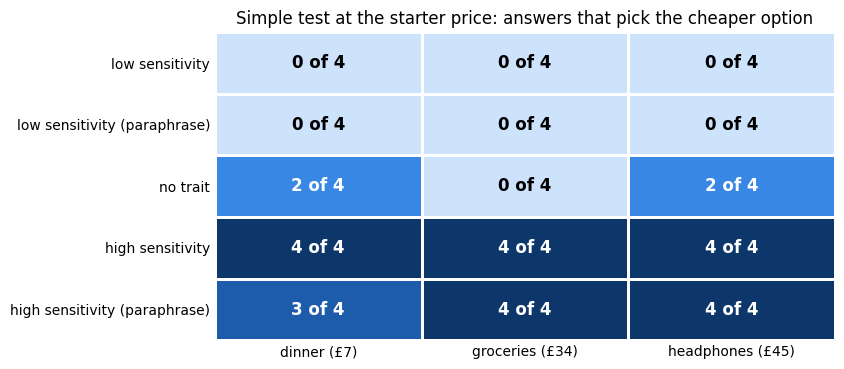

In [100]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ROWS = ["profile-01", "profile-05", "profile-03", "profile-02", "profile-06"]  # low, low paraphrase, no trait, high, high paraphrase
COLUMNS = ["dinner (£7)", "groceries (£34)", "headphones (£45)"]
BLUES = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # one colour, from light (0 of 4) to dark (4 of 4)

grid = [starter_counts[persona] for persona in ROWS]  # the table from the previous cell

fig, ax = plt.subplots(figsize=(8, 4))
ax.pcolormesh(grid, cmap=ListedColormap(BLUES), vmin=0, vmax=4, edgecolors="white", linewidth=2)
ax.invert_yaxis()  # first row on top
ax.set_xticks([0.5, 1.5, 2.5], labels=COLUMNS)  # .5 = the middle of a cell
ax.set_yticks([0.5, 1.5, 2.5, 3.5, 4.5], labels=[VERSIONS[persona] for persona in ROWS])
ax.tick_params(length=0)
ax.spines[:].set_visible(False)

for row, counts in enumerate(grid):
    for column, count in enumerate(counts):
        ax.text(column + 0.5, row + 0.5, f"{count} of 4", ha="center", va="center",
                fontsize=12, fontweight="bold", color="white" if count >= 2 else "black")

ax.set_title("Simple test at the starter price: answers that pick the cheaper option")
plt.show()

**Headline chart:** the two wordings of each sensitivity level combined, summed over the three scenarios.

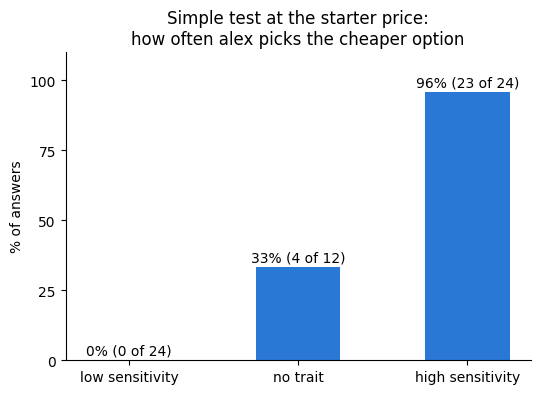

In [101]:
import matplotlib.pyplot as plt

GROUPS = {  # bar -> the alex versions combined in it
    "low sensitivity": ["profile-01", "profile-05"],
    "no trait": ["profile-03"],
    "high sensitivity": ["profile-02", "profile-06"],
}

fig, ax = plt.subplots(figsize=(6, 4))
for group, personas in GROUPS.items():
    cheaper = sum(sum(starter_counts[persona]) for persona in personas)  # summed over the 3 base-scenarios
    answers = 12 * len(personas)  # 12 answers per alex version (3 base-scenarios x 2 orders x 2 rounds)
    percent = 100 * cheaper / answers
    ax.bar(group, percent, width=0.5, color="#2a78d6")
    ax.text(group, percent + 2, f"{percent:.0f}% ({cheaper} of {answers})", ha="center")

ax.set_ylim(0, 110)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_ylabel("% of answers")
ax.set_title("Simple test at the starter price:\nhow often alex picks the cheaper option")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## part 2 analysis

Part 2 of the question asks wether sensitive alex stops paying at the same point as the control (£4, known in advance), so really whether it pays any extra, measured in small steps and compared with no-trait alex. if it pays less than 5% extra, the description is just acting as an instruction and if it pays more the description is more realistically acting as a preference.

**Price ladder chart:** the percent of answers that pick the more expensive option at each of the 28 prices, with the three scenarios combined (24 answers per point, 12 for no trait).

This cell also defines what the later cells reuse: `STEPS`, `LINES`, `all_shares`, `draw_chart` and `crossing`.

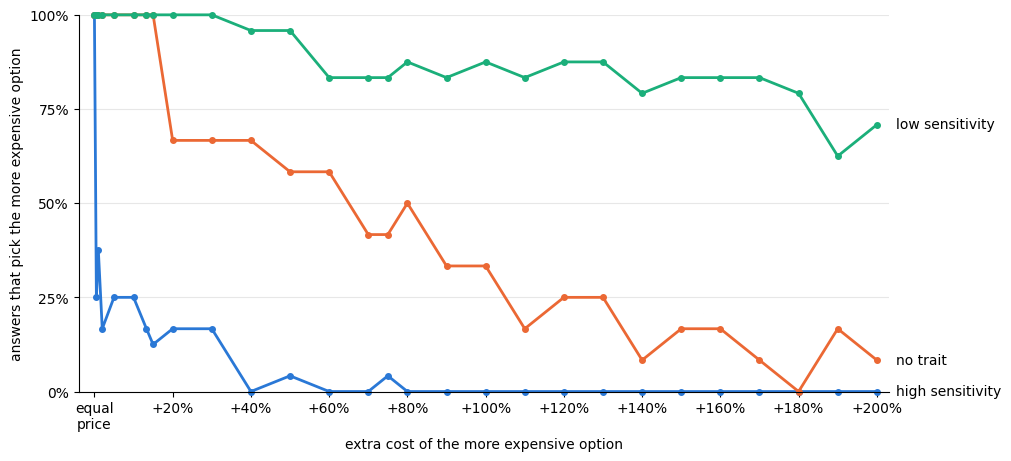

In [102]:
import matplotlib.pyplot as plt
import numpy as np

# extra cost in percent: the 14 original prices and the 14 extra prices (15%, and every 10% up to 200%)
STEPS = [0, 0.5, 1, 2, 5, 10, 13.3, 15, 20, 30, 40, 50, 60, 70, 75, 80, 90, 100,
         110, 120, 130, 140, 150, 160, 170, 180, 190, 200]
EXPENSIVE = {"dinner": "prepared", "groceries": "deliver", "headphones": "wireless"}
LINES = {  # line name -> (alex versions combined in it, colour); the last one is drawn on top
    "high sensitivity": (["profile-02", "profile-06"], "#2a78d6"),
    "no trait": (["profile-03"], "#eb6834"),
    "low sensitivity": (["profile-01", "profile-05"], "#1baf7a"),
}

all_shares = {}  # line name -> percent of answers that pick the more expensive option, at each of the 28 prices
for name, (personas, colour) in LINES.items():
    shares = []
    for step in STEPS:
        picks = [get_answer(persona, scenario, step, order, round_number)[0] == EXPENSIVE[scenario]
                 for persona in personas for scenario in EXPENSIVE
                 for order in ("original", "reversed") for round_number in (1, 2)]
        shares.append(100 * sum(picks) / len(picks))
    all_shares[name] = shares


def draw_chart():
    """Draw the part 2 line chart and return its axes, so the next cells can add the NPP or APP marks to it."""
    fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
    for name, (personas, colour) in LINES.items():
        shares = all_shares[name]
        ax.plot(STEPS, shares, color=colour, linewidth=2, marker="o", markersize=4, clip_on=False)  # x = the real extra cost
        ax.text(STEPS[-1] + 5, shares[-1], name, va="center")  # name at the right end instead of a legend

    TICKS = range(0, 201, 20)  # a label every 20%; every tested price has a marker
    ax.set_xticks(TICKS, labels=["equal\nprice"] + [f"+{step}%" for step in TICKS[1:]])
    ax.set_xlim(-4, STEPS[-1] + 3)  # the axis stops just before the line names
    ax.set_xlabel("extra cost of the more expensive option")
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100], labels=["0%", "25%", "50%", "75%", "100%"])
    ax.set_ylabel("answers that pick the more expensive option")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    
    return ax


def crossing(shares: list[float], level: float) -> float:
    """Extra cost at which a line first drops below level, on the straight line between the two tested prices around it."""
    i = next(i for i, share in enumerate(shares) if share < level)  # first price below the level
    return np.interp(level, [shares[i], shares[i - 1]], [STEPS[i], STEPS[i - 1]])


draw_chart()
plt.show()

### NPP and APP

- **NPP (never-pays point):** where a line enters the never-pays zone, under 5% of answers.
- **APP (always-pays point):** where a line leaves the always-pays zone, over 95% of answers.

On the charts, a dotted line marks where the line crosses the 5% or 95% level, and its label gives the first tested price after that crossing.

**NPP:** the never-pays zone on its own, then with the NPP of each line.

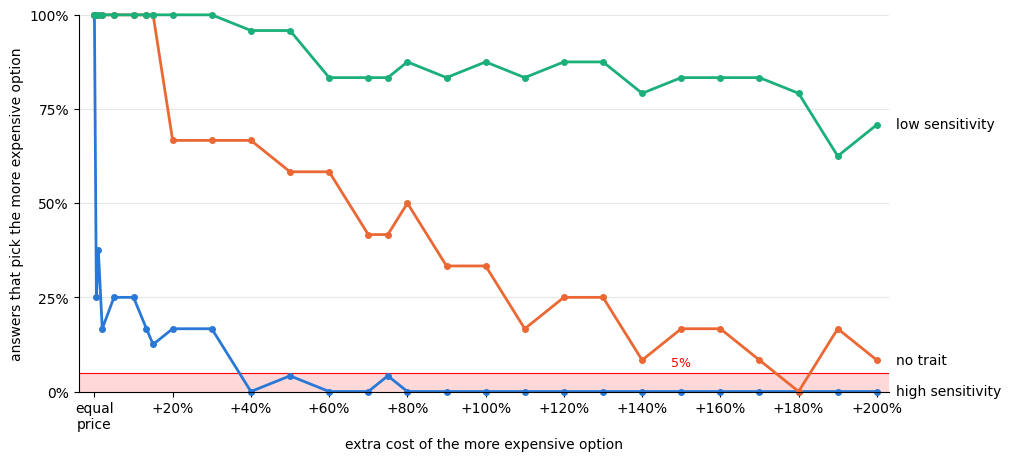

In [103]:
def add_npp(ax):
    """Add the "never pays" zone (under 5% of answers) and the NPP dotted line to a chart."""
    ax.axhspan(0, 5, color="red", alpha=0.15, linewidth=0, zorder=0)  # transparent red with a thin red edge
    ax.axhline(5, color="red", linewidth=0.8, zorder=1)
    ax.text(150, 6, "5%", color="red", fontsize=9, ha="center", va="bottom")
    


ax = draw_chart()
add_npp(ax)
plt.show()

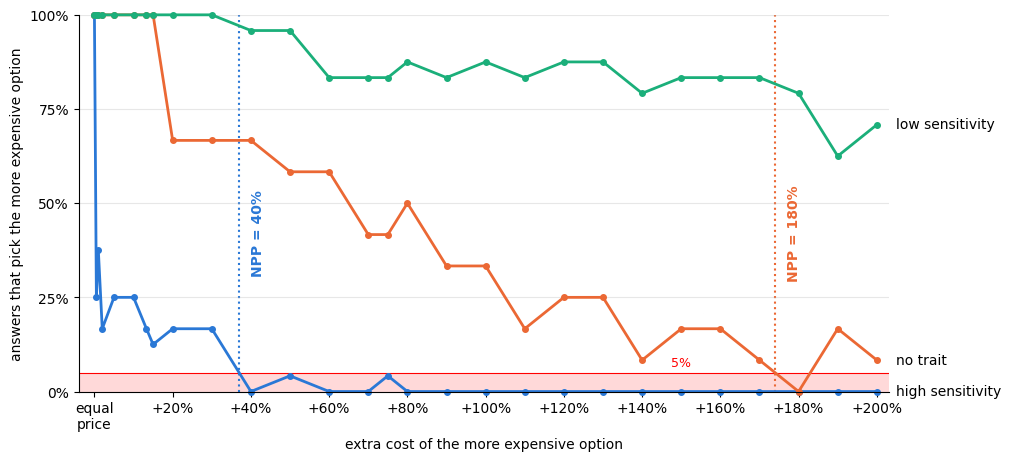

In [104]:
def add_npp(ax):
    """Add the "never pays" zone (under 5% of answers) and the NPP dotted lines, each with its value, to a chart."""
    ax.axhspan(0, 5, color="red", alpha=0.15, linewidth=0, zorder=0)  # transparent red with a thin red edge
    ax.axhline(5, color="red", linewidth=0.8, zorder=1)
    ax.text(150, 6, "5%", color="red", fontsize=9, ha="center", va="bottom")
    # NPP: dotted line where a line enters the zone, in that line's colour (only for lines that get there)
    for name, (personas, colour) in LINES.items():
        shares = all_shares[name]
        if min(shares) < 5:
            line_at = crossing(shares, 5)
            ax.axvline(line_at, color=colour, linestyle=":", zorder=1)
            npp = next(step for step, share in zip(STEPS, shares) if share < 5)  # the NPP as a tested price: the first one under 5%
            ax.text(line_at + 3, 42, f"NPP = {npp:g}%", color=colour, fontweight="bold", rotation=90, va="center")  # along the line


ax = draw_chart()
add_npp(ax)
plt.show()

**APP:** the always-pays zone on its own, then with the APP of each line.

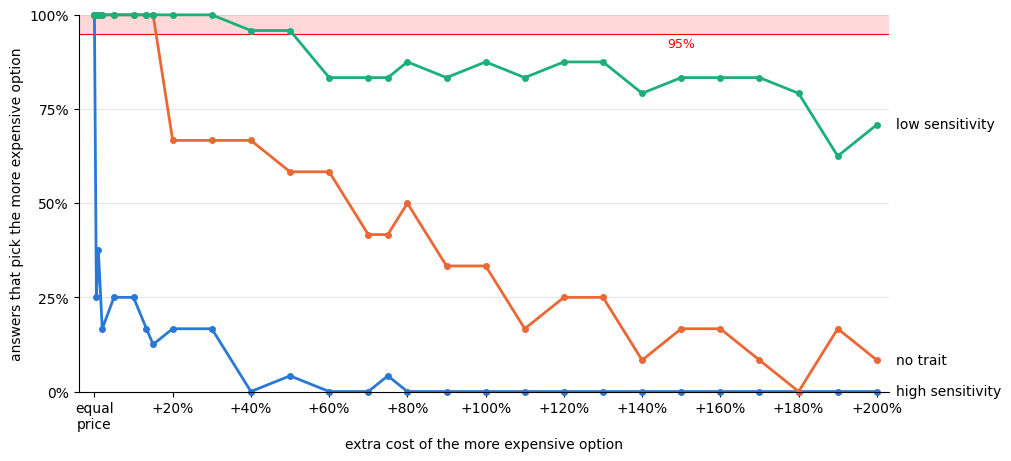

In [105]:
def add_app(ax):
    """Add the "always pays" zone (over 95% of answers) and the APP dotted lines to a chart."""
    ax.axhspan(95, 100, color="red", alpha=0.15, linewidth=0, zorder=0)  # transparent red with a thin red edge
    ax.axhline(95, color="red", linewidth=0.8, zorder=1)
    ax.text(150, 94, "95%", color="red", fontsize=9, ha="center", va="top")
    


ax = draw_chart()
add_app(ax)
plt.show()

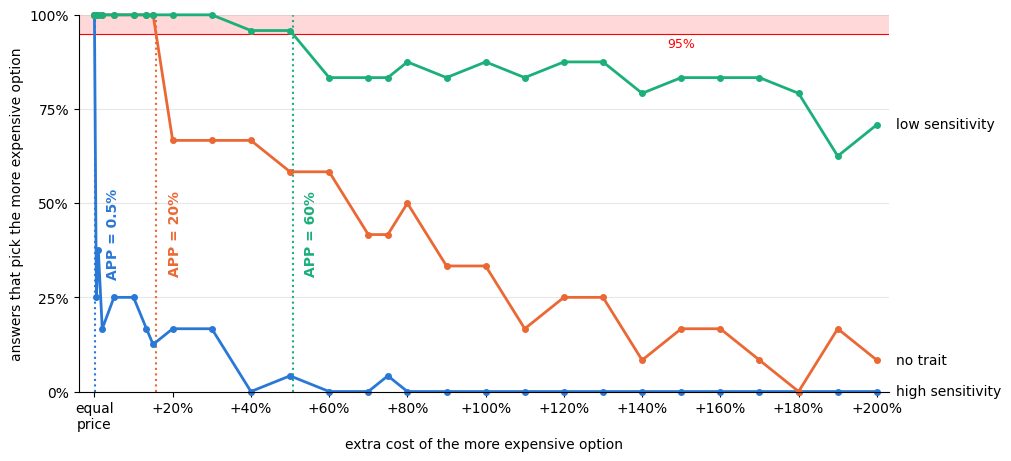

In [106]:
def add_app(ax):
    """Add the "always pays" zone (over 95% of answers) and the APP dotted lines, each with its value, to a chart."""
    ax.axhspan(95, 100, color="red", alpha=0.15, linewidth=0, zorder=0)  # transparent red with a thin red edge
    ax.axhline(95, color="red", linewidth=0.8, zorder=1)
    ax.text(150, 94, "95%", color="red", fontsize=9, ha="center", va="top")
    # APP: dotted line where each line leaves the zone, in that line's colour
    for name, (personas, colour) in LINES.items():
        shares = all_shares[name]
        line_at = crossing(shares, 95)
        ax.axvline(line_at, color=colour, linestyle=":", zorder=1)
        app = next(step for step, share in zip(STEPS, shares) if share < 95)  # the APP as a tested price: the first one under 95%
        ax.text(line_at + 3, 42, f"APP = {app:g}%", color=colour, fontweight="bold", rotation=90, va="center")  # along the line


ax = draw_chart()
add_app(ax)
plt.show()

**Both zones on one chart.**

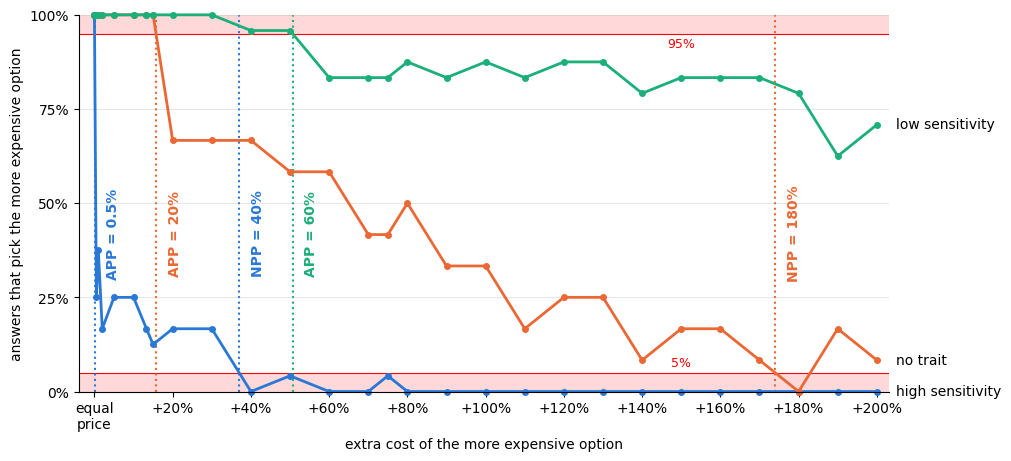

In [107]:
ax = draw_chart()  # both on one chart
add_npp(ax)
add_app(ax)
plt.show()

**Table:** NPP and APP as the crossing itself, read off the straight line between the two tested prices around it. `>200%` means the line never gets there.

In [108]:
def point(shares: list[float], level: float) -> str:
    """NPP or APP as text: the extra cost at which a line first drops below level, or ">200%" if it never does."""
    if min(shares) >= level:
        return ">200%"
    return f"{crossing(shares, level):.1f}%"


print(f"{'':<18}{'NPP':>8}{'APP':>8}")
for name in ("low sensitivity", "no trait", "high sensitivity"):
    shares = all_shares[name]  # from the chart cell above
    print(f"{name:<18}{point(shares, 5):>8}{point(shares, 95):>8}")

                       NPP     APP
low sensitivity      >200%   50.7%
no trait            174.0%   15.8%
high sensitivity     37.0%    0.0%


### per scenario

The same chart for each scenario on its own (8 answers per point, 4 for no trait). The black line is the starter price used in part 1.

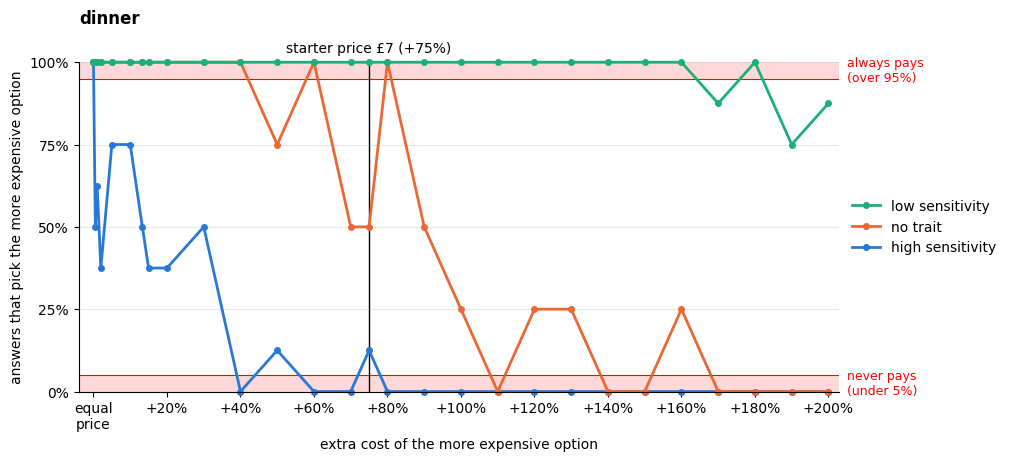

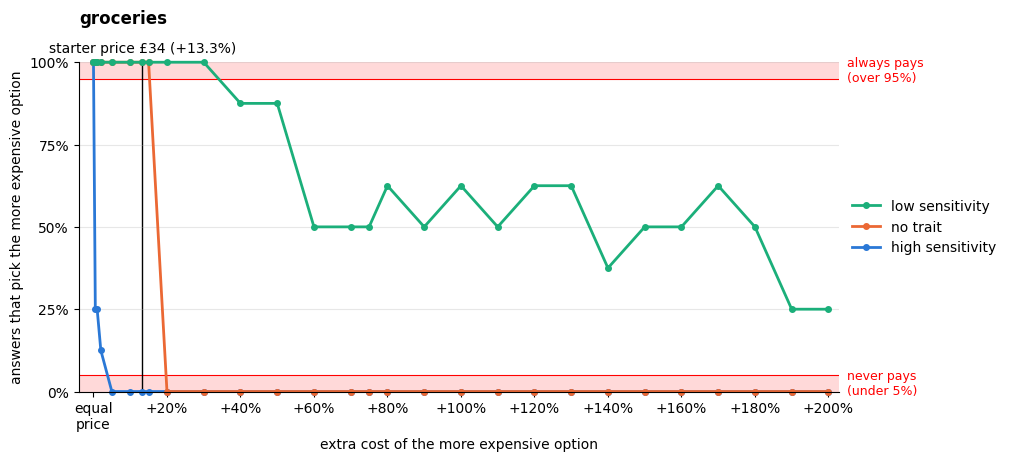

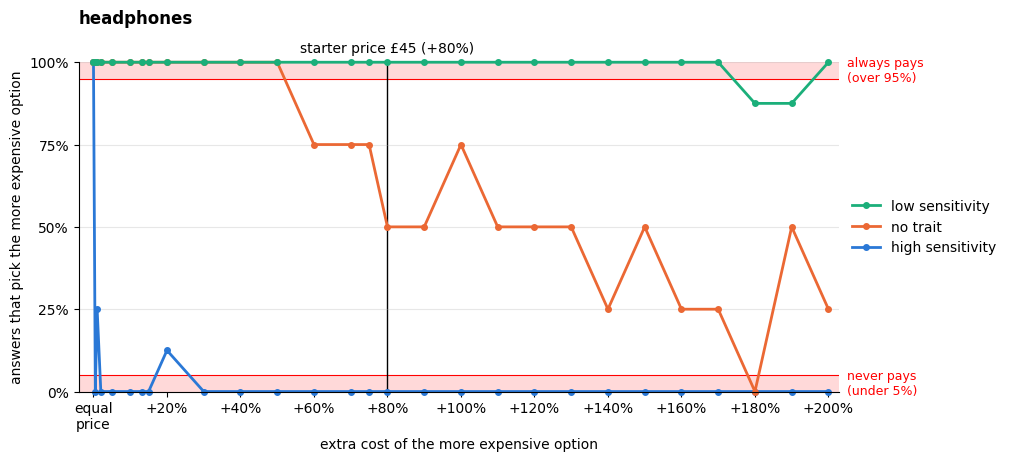

In [116]:
STARTER_PRICE = {"dinner": "£7", "groceries": "£34", "headphones": "£45"}  # price of the more expensive option in the starter pack
scenario_shares = {}  # (scenario, line name) -> percent of answers that pick the more expensive option, at each of the 28 prices

for scenario in EXPENSIVE:  # one chart per scenario: dinner, groceries, headphones
    fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
    for name, (personas, colour) in LINES.items():
        shares = []
        for step in STEPS:
            picks = [get_answer(persona, scenario, step, order, round_number)[0] == EXPENSIVE[scenario]
                     for persona in personas for order in ("original", "reversed") for round_number in (1, 2)]
            shares.append(100 * sum(picks) / len(picks))
        scenario_shares[scenario, name] = shares
        ax.plot(STEPS, shares, color=colour, linewidth=2, marker="o", markersize=4, clip_on=False, label=name)

    # the two red zones, named in the right margin
    ax.axhspan(0, 5, color="red", alpha=0.15, linewidth=0, zorder=0)
    ax.axhspan(95, 100, color="red", alpha=0.15, linewidth=0, zorder=0)
    ax.axhline(5, color="red", linewidth=0.8, zorder=1)
    ax.axhline(95, color="red", linewidth=0.8, zorder=1)
    ax.text(STEPS[-1] + 5, 97.5, "always pays\n(over 95%)", color="red", fontsize=9, va="center")
    ax.text(STEPS[-1] + 5, 2.5, "never pays\n(under 5%)", color="red", fontsize=9, va="center")

    # black line at the starter price, with that price written above it
    starter = STARTER_PERCENT[scenario]  # from the part 1 cell
    ax.axvline(starter, color="black", linewidth=1, zorder=1)
    ax.text(starter, 102, f"starter price {STARTER_PRICE[scenario]} (+{starter:g}%)", ha="center", va="bottom")

    ax.set_title(f"{scenario}", loc="left", pad=28, fontweight="bold")
    handles, names = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], names[::-1], loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)  # in the right margin: low, no trait, high
    TICKS = range(0, 201, 20)
    ax.set_xticks(TICKS, labels=["equal\nprice"] + [f"+{step}%" for step in TICKS[1:]])
    ax.set_xlim(-4, STEPS[-1] + 3)
    ax.set_xlabel("extra cost of the more expensive option")
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100], labels=["0%", "25%", "50%", "75%", "100%"])
    ax.set_ylabel("answers that pick the more expensive option")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

**Table:** NPP and APP per scenario, as crossing values. `*` marks a flip back: the line returns to the level at a higher price.

In [111]:
def point_flagged(shares: list[float], level: float) -> str:
    """NPP or APP as text, with a * if the line gets back to the level or above at a higher price (a flip back)."""
    text = point(shares, level)  # from the NPP and APP table cell
    if text != ">200%":
        first = next(i for i, share in enumerate(shares) if share < level)  # first price below the level
        if max(shares[first:]) >= level:
            text += "*"
    return text


print(f"{'':<30}{'NPP':>9}{'APP':>9}")
for scenario in EXPENSIVE:  # dinner, groceries, headphones
    for name in ("low sensitivity", "no trait", "high sensitivity"):
        shares = scenario_shares[scenario, name]  # from the per-scenario chart cell above
        print(f"{scenario:<12}{name:<18}{point_flagged(shares, 5):>9}{point_flagged(shares, 95):>9}")
    print()
print("* flip back: the line returns to the 5% or 95% level, or above it, at a higher price")

                                    NPP      APP
dinner      low sensitivity       >200%  164.0%*
dinner      no trait            108.0%*   42.0%*
dinner      high sensitivity     39.0%*     0.0%

groceries   low sensitivity       >200%    34.0%
groceries   no trait              19.8%    15.2%
groceries   high sensitivity       3.8%     0.0%

headphones  low sensitivity       >200%  174.0%*
headphones  no trait            178.0%*    52.0%
headphones  high sensitivity      0.5%*     0.0%

* flip back: the line returns to the 5% or 95% level, or above it, at a higher price


### switching point

Where a line first drops below half of the answers. The dotted line marks the crossing of the 50% level, and its label gives the first tested price below 50%.

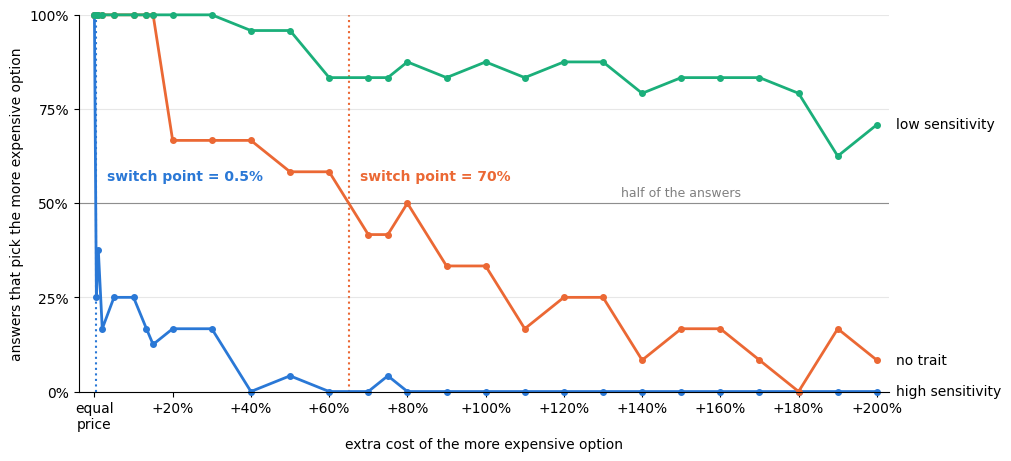

In [109]:
def add_switching_point(ax):
    """Add the 50% line and, per line, a dotted line with its value at the switching point (where it first drops below 50% of answers)."""
    ax.axhline(50, color="grey", linewidth=0.8, zorder=1)
    ax.text(150, 51, "half of the answers", color="grey", fontsize=9, ha="center", va="bottom")
    # dotted line in the line's own colour (only for lines that drop below 50%)
    for name, (personas, colour) in LINES.items():
        shares = all_shares[name]
        if min(shares) < 50:
            switch = crossing(shares, 50)
            ax.axvline(switch, color=colour, linestyle=":", zorder=1)
            first_below = next(step for step, share in zip(STEPS, shares) if share < 50)  # the switch point as a tested price
            ax.text(switch + 3, 57, f"switch point = {first_below:g}%", color=colour, fontweight="bold", va="center")


ax = draw_chart()
add_switching_point(ax)
plt.show()

## checks: option order and persona wording

Both charts count every price, scenario and round, and show the percent of answers that pick the more expensive option.

### option order

Answers split by which option is listed first.

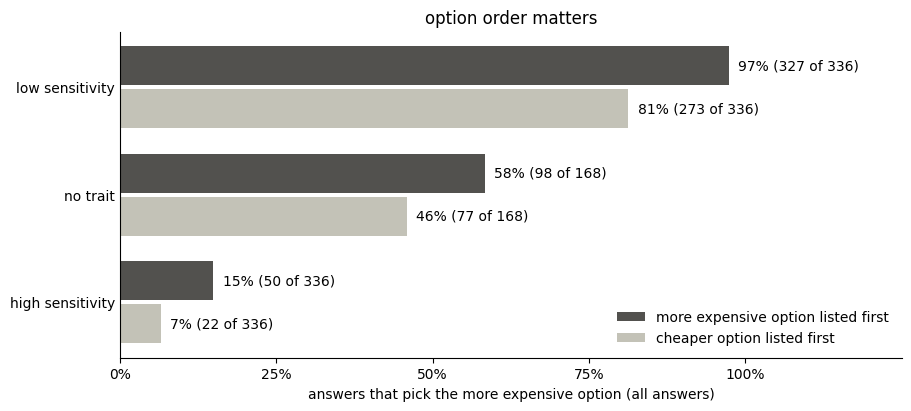

In [112]:
# the option order that lists the more expensive option first, per scenario (the other order lists the cheaper one first)
EXPENSIVE_FIRST = {"dinner": "reversed", "groceries": "original", "headphones": "reversed"}
BARS = {  # bar label -> (is the more expensive option listed first?, colour)
    "more expensive option listed first": (True, "#52514e"),
    "cheaper option listed first": (False, "#c3c2b7"),
}

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
for row, (group, personas) in enumerate(GROUPS.items()):  # split 1: low sensitivity, no trait, high sensitivity
    for bar, (label, (expensive_first, colour)) in enumerate(BARS.items()):  # split 2: which option is listed first
        # all answers of this group with this option order (every price, scenario and round); True = picks the more expensive option
        picks = [get_answer(persona, scenario, step, order, round_number)[0] == EXPENSIVE[scenario]
                 for persona in personas for scenario in EXPENSIVE for step in STEPS
                 for order in ("original", "reversed") for round_number in (1, 2)
                 if (order == EXPENSIVE_FIRST[scenario]) == expensive_first]
        share = 100 * sum(picks) / len(picks)
        y = row + (bar - 0.5) * 0.4  # the two bars of a group sit next to each other
        ax.barh(y, share, height=0.36, color=colour, label=label if row == 0 else None)
        ax.text(share + 1.5, y, f"{share:.0f}% ({sum(picks)} of {len(picks)})", va="center")

ax.set_yticks(range(len(GROUPS)), labels=GROUPS)
ax.invert_yaxis()  # first group on top
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 125)  # room for the text at the end of the longest bar
ax.set_xticks([0, 25, 50, 75, 100], labels=["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("answers that pick the more expensive option (all answers)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False)
ax.set_title("option order matters")
plt.show()

### persona rephrasing

The original wording against the paraphrase, for low and high sensitivity. No trait has only one wording.

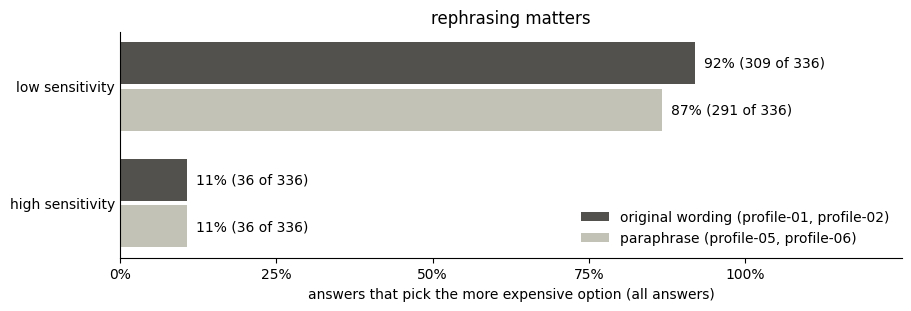

In [114]:
# the two wordings of each sensitivity level: (original wording, paraphrase); no trait has only one wording
WORDINGS = {"low sensitivity": ("profile-01", "profile-05"), "high sensitivity": ("profile-02", "profile-06")}
WORDING_BARS = {"original wording (profile-01, profile-02)": "#52514e", "paraphrase (profile-05, profile-06)": "#c3c2b7"}  # label -> colour

fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
for row, (group, personas) in enumerate(WORDINGS.items()):  # split 1: low sensitivity, high sensitivity
    for bar, (persona, (label, colour)) in enumerate(zip(personas, WORDING_BARS.items())):  # split 2: the wording
        # all answers of this alex version (every price, scenario, order and round); True = picks the more expensive option
        picks = [get_answer(persona, scenario, step, order, round_number)[0] == EXPENSIVE[scenario]
                 for scenario in EXPENSIVE for step in STEPS
                 for order in ("original", "reversed") for round_number in (1, 2)]
        share = 100 * sum(picks) / len(picks)
        y = row + (bar - 0.5) * 0.4  # the two bars of a group sit next to each other
        ax.barh(y, share, height=0.36, color=colour, label=label if row == 0 else None)
        ax.text(share + 1.5, y, f"{share:.0f}% ({sum(picks)} of {len(picks)})", va="center")

ax.set_yticks(range(len(WORDINGS)), labels=WORDINGS)
ax.invert_yaxis()  # first group on top
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 125)  # room for the text at the end of the longest bar
ax.set_xticks([0, 25, 50, 75, 100], labels=["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("answers that pick the more expensive option (all answers)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False)
ax.set_title("rephrasing matters")
plt.show()